# Black-Scholes options lab: the model and where it breaks

This notebook is the narrative behind the repository. It builds the model step by step, verifies each piece, then tests it against real option quotes.

1. Pricing with the closed-form formula
2. Greeks: how the risk of an option changes with spot and maturity
3. Monte Carlo: an independent route to the same price
4. Implied volatility: inverting the formula
5. Market data: what real quotes say about the constant-volatility assumption

All library code lives in `src/bs_lab/`. Every number below comes from running this notebook.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bs_lab import greeks
from bs_lab.pricing import call_price, put_price

FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.labelcolor": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "legend.frameon": False, "legend.labelcolor": INK,
})

# Reference option used in the first sections.
K, R, SIGMA = 100.0, 0.03, 0.20

## 1. Pricing

The price is the discounted expected payoff under a risk-neutral world. The stock's expected return does not appear, because the option can be hedged with the stock. Only volatility remains as an unobservable input, which is the source of everything in section 5.

Put-call parity, $C - P = Se^{-qT} - Ke^{-rT}$, is a pure no-arbitrage identity and is checked in `tests/test_pricing.py`.

In [2]:
S, T = 100.0, 1.0
call, put = call_price(S, K, T, R, SIGMA), put_price(S, K, T, R, SIGMA)
parity_gap = (call - put) - (S - K * np.exp(-R * T))
print(f"ATM 1Y call {call:.4f} | put {put:.4f} | parity gap {parity_gap:.1e}")

ATM 1Y call 9.4134 | put 6.4580 | parity gap 0.0e+00


## 2. Greeks

Greeks are the sensitivities a desk manages. They are plotted in practical units: vega and rho per 1 point, theta per calendar day. The closed forms are checked against finite differences in `tests/test_greeks.py`.

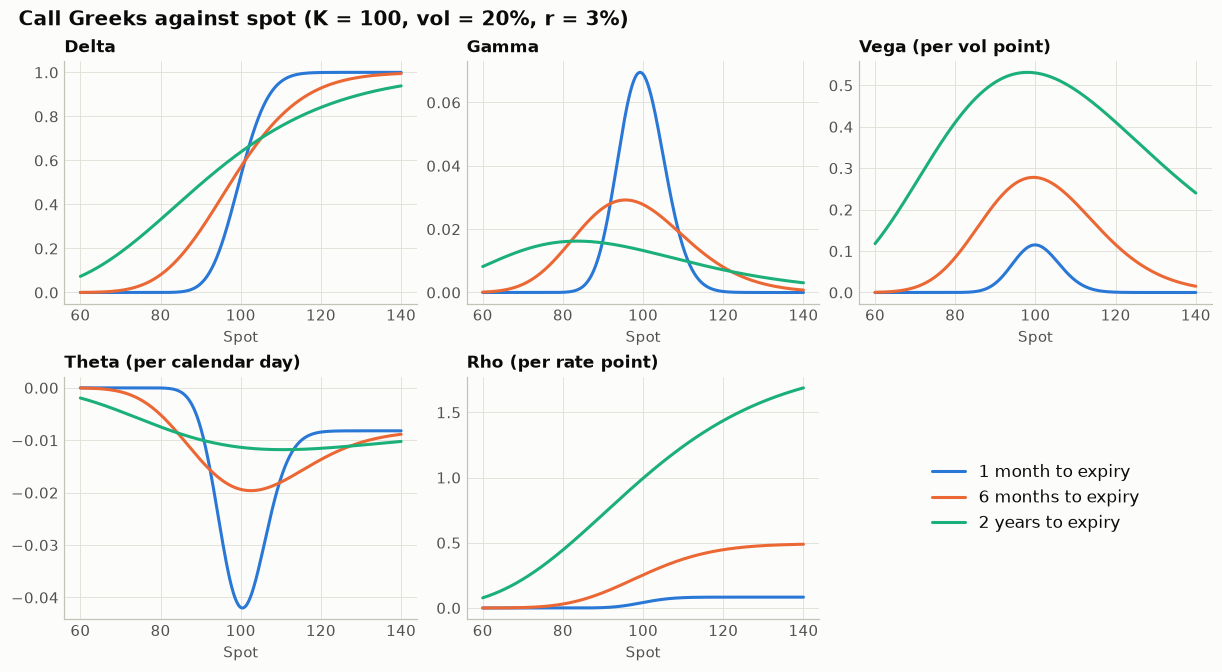

In [3]:
def greek_panels(x, series, xlabel, title, path):
    """Plot the five Greeks of a call as small multiples sharing one legend."""
    panels = [
        ("Delta", lambda a: greeks.delta(*a)),
        ("Gamma", lambda a: greeks.gamma(*a)),
        ("Vega (per vol point)", lambda a: greeks.vega(*a) / 100),
        ("Theta (per calendar day)", lambda a: greeks.theta(*a) / 365),
        ("Rho (per rate point)", lambda a: greeks.rho(*a) / 100),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    for ax, (name, compute) in zip(axes.flat, panels):
        for label, color, args in series:
            ax.plot(x, compute(args), color=color, label=label)
        ax.set_title(name)
        ax.set_xlabel(xlabel)
    legend_ax = axes.flat[-1]
    legend_ax.axis("off")
    legend_ax.legend(*axes.flat[0].get_legend_handles_labels(), loc="center", fontsize=11)
    fig.savefig(path)
    plt.show()


spots = np.linspace(60, 140, 401)
series = [
    (f"{label} to expiry", color, (spots, K, T, R, SIGMA))
    for label, T, color in [("1 month", 1 / 12, BLUE), ("6 months", 0.5, ORANGE), ("2 years", 2.0, AQUA)]
]
greek_panels(spots, series, "Spot", f"Call Greeks against spot (K = {K:.0f}, vol = {SIGMA:.0%}, r = {R:.0%})",
             FIGURES / "greeks_vs_spot.png")

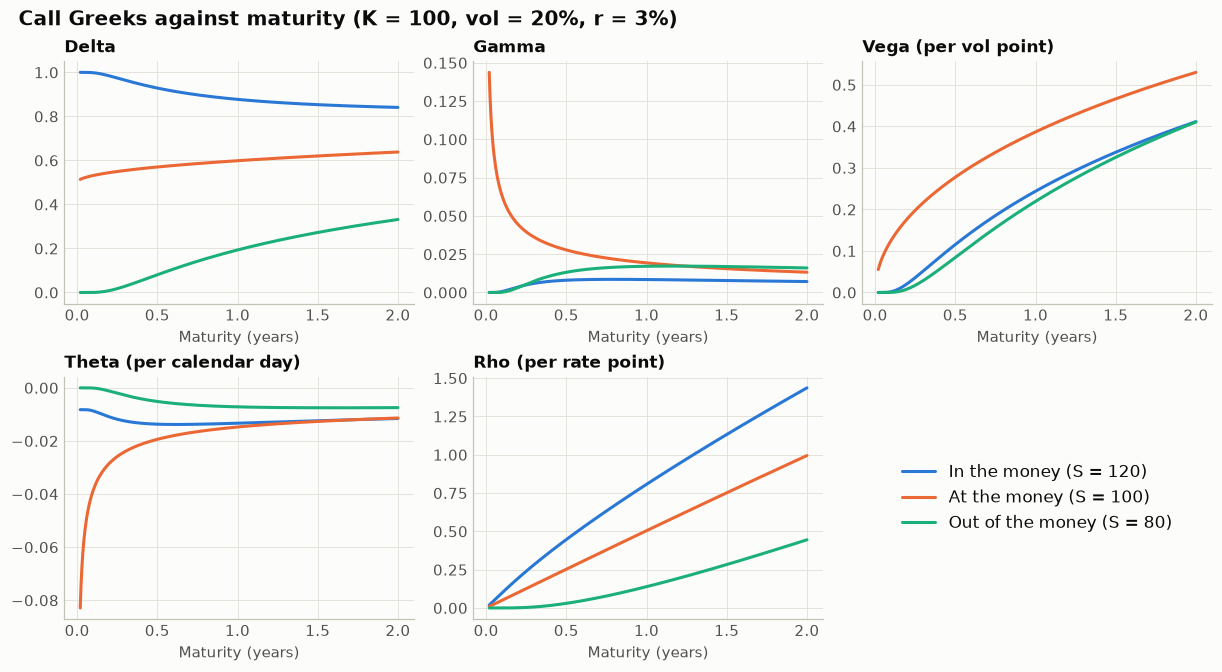

In [4]:
maturities = np.linspace(1 / 52, 2, 400)
series = [
    (label, color, (S, K, maturities, R, SIGMA))
    for label, S, color in [("In the money (S = 120)", 120.0, BLUE), ("At the money (S = 100)", 100.0, ORANGE), ("Out of the money (S = 80)", 80.0, AQUA)]
]
greek_panels(maturities, series, "Maturity (years)", f"Call Greeks against maturity (K = {K:.0f}, vol = {SIGMA:.0%}, r = {R:.0%})",
             FIGURES / "greeks_vs_maturity.png")

In [5]:
week, year = 1 / 52, 1.0
print(f"ATM gamma: {greeks.gamma(100, K, week, R, SIGMA):.4f} at 1 week vs {greeks.gamma(100, K, year, R, SIGMA):.4f} at 1 year")
print(f"ATM vega per point: {greeks.vega(100, K, week, R, SIGMA) / 100:.4f} at 1 week vs {greeks.vega(100, K, year, R, SIGMA) / 100:.4f} at 1 year")
print(f"ATM theta per day: {greeks.theta(100, K, week, R, SIGMA) / 365:.4f} at 1 week vs {greeks.theta(100, K, year, R, SIGMA) / 365:.4f} at 1 year")

ATM gamma: 0.1438 at 1 week vs 0.0193 at 1 year
ATM vega per point: 0.0553 at 1 week vs 0.3867 at 1 year
ATM theta per day: -0.0829 at 1 week vs -0.0147 at 1 year


**Reading the charts.** Short-dated at-the-money options carry the most gamma and the most time decay: the hedge changes fast and the position pays for that every day. Long-dated options carry the most vega, which is why they are the natural instrument for a view on volatility. The figures above quantify both effects.

## 3. Monte Carlo

Monte Carlo computes the same risk-neutral expectation by simulation, with no use of the closed form. If the two agree, each confirms the other.

The chart runs 200 independent experiments at each sample size. This measures the actual error, instead of showing one lucky or unlucky run, and lets us fit the convergence rate rather than assume it.

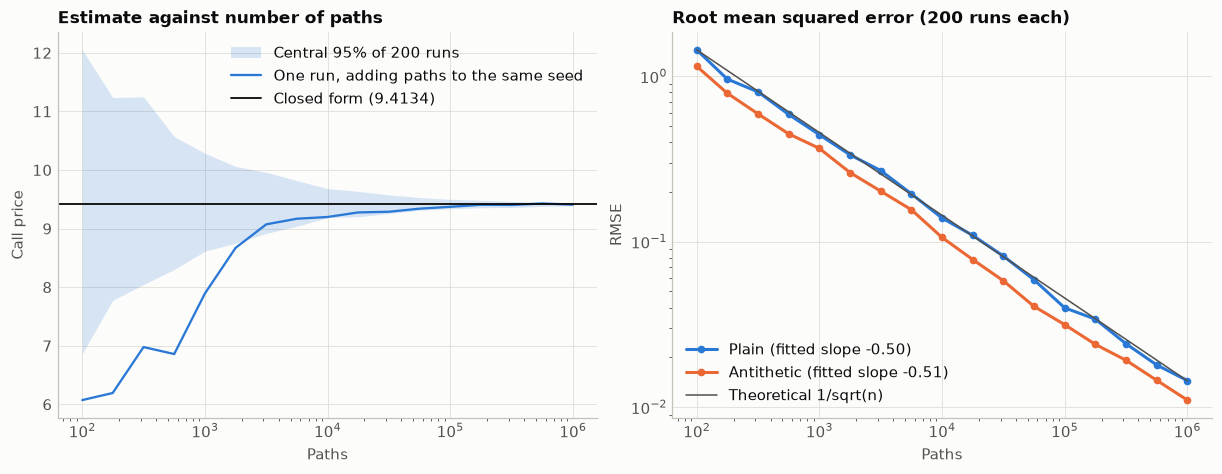

Closed form 9.4134
RMSE at 1,000,000 paths: plain 0.0145 (0.154% of price), antithetic 0.0110
Fitted slopes: plain -0.501, antithetic -0.506 (theory -0.5)
Variance ratio, plain / antithetic: 1.60


In [6]:
from bs_lab.montecarlo import mc_price

S0, T0 = 100.0, 1.0
exact = call_price(S0, K, T0, R, SIGMA)
sizes = np.unique(np.logspace(2, 6, 17).astype(int))
n_runs = 200

rows = []
for antithetic in (False, True):
    for n in sizes:
        runs = [mc_price(S0, K, T0, R, SIGMA, int(n), seed=1000 * i + int(n), antithetic=antithetic) for i in range(n_runs)]
        errors = np.array([run.price - exact for run in runs])
        rows.append({"antithetic": antithetic, "n_paths": n, "rmse": np.sqrt(np.mean(errors**2)),
                     "low": np.quantile(errors, 0.025), "high": np.quantile(errors, 0.975),
                     "mean_se": np.mean([run.std_error for run in runs])})
convergence = pd.DataFrame(rows)

plain = convergence[~convergence.antithetic]
mirrored = convergence[convergence.antithetic]
slope_plain = np.polyfit(np.log(plain.n_paths), np.log(plain.rmse), 1)[0]
slope_mirrored = np.polyfit(np.log(mirrored.n_paths), np.log(mirrored.rmse), 1)[0]

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
left.fill_between(plain.n_paths, exact + plain.low, exact + plain.high, color=BLUE, alpha=0.18, linewidth=0, label="Central 95% of 200 runs")
single = [mc_price(S0, K, T0, R, SIGMA, int(n), seed=7).price for n in sizes]
left.plot(sizes, single, color=BLUE, linewidth=1.5, label="One run, adding paths to the same seed")
left.axhline(exact, color=INK, linewidth=1.2, label=f"Closed form ({exact:.4f})")
left.set_xscale("log")
left.set_title("Estimate against number of paths")
left.set_xlabel("Paths")
left.set_ylabel("Call price")
left.legend(loc="upper right")

right.loglog(plain.n_paths, plain.rmse, color=BLUE, marker="o", markersize=4, label=f"Plain (fitted slope {slope_plain:.2f})")
right.loglog(mirrored.n_paths, mirrored.rmse, color=ORANGE, marker="o", markersize=4, label=f"Antithetic (fitted slope {slope_mirrored:.2f})")
reference = plain.rmse.iloc[0] * np.sqrt(plain.n_paths.iloc[0] / plain.n_paths)
right.loglog(plain.n_paths, reference, color=MUTED, linewidth=1, label="Theoretical 1/sqrt(n)")
right.set_title("Root mean squared error (200 runs each)")
right.set_xlabel("Paths")
right.set_ylabel("RMSE")
right.legend(loc="lower left")
fig.savefig(FIGURES / "mc_convergence.png")
plt.show()

top_plain, top_mirrored = plain.iloc[-1], mirrored.iloc[-1]
print(f"Closed form {exact:.4f}")
print(f"RMSE at {top_plain.n_paths:,} paths: plain {top_plain.rmse:.4f} ({top_plain.rmse / exact:.3%} of price), antithetic {top_mirrored.rmse:.4f}")
print(f"Fitted slopes: plain {slope_plain:.3f}, antithetic {slope_mirrored:.3f} (theory -0.5)")
print(f"Variance ratio, plain / antithetic: {(plain.rmse.values**2).mean() / (mirrored.rmse.values**2).mean():.2f}")

**Reading the chart.** The fitted slope is close to -0.5, which is the $1/\sqrt{n}$ law: to halve the error you need four times the paths. That is why Monte Carlo is a tool of last resort for simple payoffs and a necessity for path-dependent ones. Antithetic sampling lowers the level of the error but not its rate.

## 4. Implied volatility

Volatility is the only input that cannot be observed, so the market runs the formula backwards: given a price, which volatility produces it? This section checks the solver on a known grid before pointing it at real quotes.

In [7]:
from bs_lab.implied_vol import solve_implied_vol

strikes, maturities, vols = np.meshgrid(np.linspace(60, 150, 46), np.array([0.05, 0.25, 1.0, 3.0]), np.linspace(0.05, 1.5, 30))
prices = call_price(100.0, strikes, maturities, R, vols)
solved = solve_implied_vol(prices, 100.0, strikes, maturities, R)
priced = np.isfinite(solved.vol)
repricing_error = np.abs(call_price(100.0, strikes[priced], maturities[priced], R, solved.vol[priced]) - prices[priced])

print(f"Options on the grid: {prices.size:,}")
print(f"Solved: {priced.sum():,} | rejected as no-arbitrage or zero price: {(~priced).sum():,}")
print(f"Needed the bisection fallback: {solved.used_bisection.sum():,} ({solved.used_bisection.mean():.1%})")
print(f"Largest repricing error: {repricing_error.max():.1e}")

Options on the grid: 5,520
Solved: 5,450 | rejected as no-arbitrage or zero price: 70
Needed the bisection fallback: 906 (16.4%)
Largest repricing error: 8.4e-10


## 5. Market data: testing the constant-volatility assumption

If Black-Scholes were literally true, one volatility would price every option on an underlying. This section tests that on S&P 500 index options, which are European and so match the model's exercise style.

**Method.** Only bid and ask are used. The forward and discount factor come from put-call parity on the option quotes, not from Yahoo's spot, because a delayed spot would not line up with the option quotes. Strikes that break parity are removed, and only out-of-the-money options are kept.

**Data.** Raw quotes are not published with this repository, because Yahoo's terms cover personal use. The outputs saved in this notebook and the commentary below come from a private snapshot taken on 2026-10-30. Without that snapshot, the next cell downloads current quotes: results then differ from the commentary and the figures go to `figures/live/`. If the download fails, the notebook says so, skips the market cells and shows the exported figures instead.

In [8]:
from IPython.display import Image, display

from bs_lab.implied_vol import implied_vol
from bs_lab.market_data import (MarketDataUnavailable, at_the_money_vol, build_smile, flat_vol_gap,
                                implied_forward, obtain_snapshot, parity_misses, return_statistics,
                                term_summary)

REFERENCE_DATE = "2026-10-30"  # The snapshot behind the README and the commentary.

try:
    snapshot = obtain_snapshot("../data", REFERENCE_DATE)
except MarketDataUnavailable as error:
    snapshot = None
    print(f"MARKET DATA UNAVAILABLE. {error}")
    print("The market cells below are skipped. These are the figures exported from the reference run:")
    for name in ("smile_spx.png", "return_evidence.png"):
        display(Image(filename=str(FIGURES / name), width=900))

if snapshot is not None:
    quotes, close, treasuries = snapshot.quotes, snapshot.close, snapshot.treasuries.set_index("ticker")
    market_figures = FIGURES if snapshot.date == REFERENCE_DATE else FIGURES / "live"
    market_figures.mkdir(exist_ok=True)
    if snapshot.downloaded:
        print(f"NEW DATA: reference snapshot not found, downloaded quotes for {snapshot.date}.")
        print(f"Numbers below differ from the README and the commentary. Figures go to {market_figures}.")

    spot = float(quotes["spot"].iloc[0])
    print(f"Snapshot {quotes['quote_time'].iloc[0]:%Y-%m-%d %H:%M} UTC | ^SPX {spot:,.2f} | day change {close.iloc[-1] / close.iloc[-2] - 1:+.2%}")

    fits = {expiry: implied_forward(group) for expiry, group in quotes.groupby("expiry")}
    smile = build_smile(quotes)
    live = quotes[(quotes["bid"] > 0) & (quotes["ask"] > quotes["bid"])]
    funnel = pd.Series({
        "All quotes in the snapshot": len(quotes),
        "With a live two-sided quote": len(live),
        "Strikes flagged by the parity check": sum(len(fit.bad_strikes) for fit in fits.values()),
        "Options kept in the final smile": len(smile),
    })
    print(funnel.to_string())

Snapshot 2026-10-30 18:44 UTC | ^SPX 7,537.69 | day change -2.36%
All quotes in the snapshot             1919
With a live two-sided quote            1888
Strikes flagged by the parity check      88
Options kept in the final smile         518


In [9]:
if snapshot is not None:
    # Two checks on what the free data can be trusted for.
    paired = live.assign(mid=0.5 * (live["bid"] + live["ask"]))
    stale_last = ((paired["last"] < paired["bid"]) | (paired["last"] > paired["ask"])).mean()

    near = []
    for expiry, group in paired.groupby("expiry"):
        fit = fits[expiry]
        wide = group[group["strike"].isin(fit.good_strikes) & (group["strike"] / fit.forward).between(0.95, 1.05)]
        table = wide.pivot_table(index="strike", columns="option_type", values=["mid", "vendor_iv"]).dropna()
        strikes_near = table.index.to_numpy()
        args = (fit.forward, strikes_near, fit.T, fit.rate)
        near.append(pd.DataFrame({
            "ours": np.abs(implied_vol(table["mid"]["call"].to_numpy(), *args, "call", fit.rate)
                           - implied_vol(table["mid"]["put"].to_numpy(), *args, "put", fit.rate)),
            "yahoo": np.abs(table["vendor_iv"]["call"] - table["vendor_iv"]["put"]).to_numpy(),
        }))
    near = pd.concat(near)
    print(f"Last trade outside the current bid-ask: {stale_last:.0%} of live quotes")
    print(f"Call vol minus put vol at the same strike, within 5% of the forward ({len(near)} strikes):")
    print(f"  this project: median {near['ours'].median() * 100:.2f} vol points")
    print(f"  Yahoo's implied vol column: median {near['yahoo'].median() * 100:.2f} vol points")

    index_fall = close.iloc[-2] - close.iloc[-1]
    print(f"\nParity-flagged strikes per expiry, and the typical miss in index points (the index fell {index_fall:.0f} today):")
    for expiry, group in quotes.groupby("expiry"):
        fit = fits[expiry]
        flagged = parity_misses(group, fit).loc[list(fit.bad_strikes)]
        if len(flagged):
            print(f"  {expiry.date()}: {len(flagged)} flagged, median miss {flagged.median():+.0f}, fit noise {fit.noise:.2f}")
        else:
            print(f"  {expiry.date()}: none flagged")

Last trade outside the current bid-ask: 92% of live quotes
Call vol minus put vol at the same strike, within 5% of the forward (274 strikes):
  this project: median 0.04 vol points
  Yahoo's implied vol column: median 4.64 vol points

Parity-flagged strikes per expiry, and the typical miss in index points (the index fell 183 today):
  2026-11-30: 28 flagged, median miss +174, fit noise 0.94
  2027-01-29: 29 flagged, median miss +142, fit noise 0.93
  2027-04-16: 30 flagged, median miss +160, fit noise 0.92
  2027-10-15: 1 flagged, median miss +164, fit noise 0.65


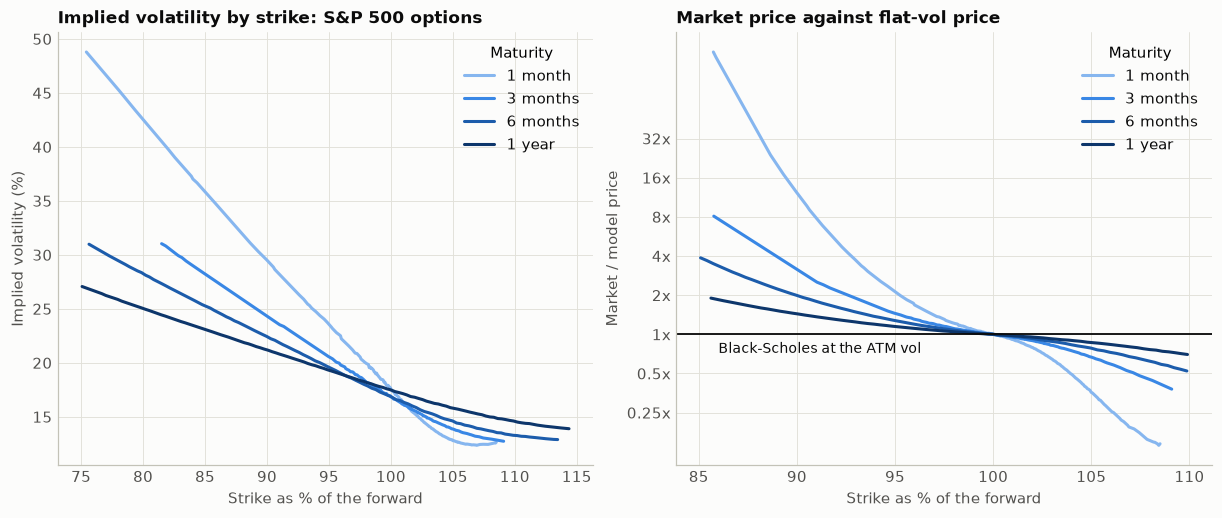

In [10]:
if snapshot is not None:
    gaps = flat_vol_gap(smile)
    atm = at_the_money_vol(smile)
    RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
    label = lambda T: {1: "1 month", 12: "1 year"}.get(round(T * 12), f"{round(T * 12)} months")

    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
    for (expiry, group), color in zip(gaps.groupby("expiry"), RAMP):
        view = group[group["moneyness"].between(0.75, 1.15)]
        name = label(view["T"].iloc[0])
        left.plot(view["moneyness"] * 100, view["iv"] * 100, color=color, label=name)
        centre = view[view["moneyness"].between(0.85, 1.10)]
        right.plot(centre["moneyness"] * 100, centre["ratio"], color=color, label=name)

    left.set_title("Implied volatility by strike: S&P 500 options")
    left.set_xlabel("Strike as % of the forward")
    left.set_ylabel("Implied volatility (%)")
    left.legend(title="Maturity", loc="upper right")

    right.axhline(1.0, color=INK, linewidth=1.2)
    right.annotate("Black-Scholes at the ATM vol", (100, 1.0), xytext=(86, 0.72), color=INK, fontsize=9)
    right.set_yscale("log")
    right.set_yticks([0.25, 0.5, 1, 2, 4, 8, 16, 32], labels=["0.25x", "0.5x", "1x", "2x", "4x", "8x", "16x", "32x"])
    right.minorticks_off()
    right.set_title("Market price against flat-vol price")
    right.set_xlabel("Strike as % of the forward")
    right.set_ylabel("Market / model price")
    right.legend(title="Maturity", loc="upper right")
    fig.savefig(market_figures / "smile_spx.png")
    plt.show()

In [11]:
if snapshot is not None:
    def nearest_row(group, level):
        return group.iloc[(group["moneyness"] - level).abs().argmin()]

    rows = []
    for expiry, group in gaps.groupby("expiry"):
        for level in (0.90, 1.10):
            row = nearest_row(group, level)
            rows.append({"expiry": expiry.date(), "T": row["T"], "type": row["option_type"], "K/F": row["moneyness"],
                         "vol": row["iv"], "flat_vol": row["flat_vol"], "market_over_flat_price": row["ratio"]})
    gap_table = pd.DataFrame(rows)
    print(gap_table.to_string(index=False, float_format=lambda x: f"{x:,.3f}"))

    central = smile[smile["moneyness"].between(0.9, 1.1)]
    print(f"\nMedian bid-ask width in vol terms, strikes within 10% of the forward: {(central['iv_ask'] - central['iv_bid']).median() * 100:.2f} vol points")
    print(f"Smallest skew across maturities (90% strike minus ATM): {term_summary(smile, spot)['skew_90_100'].min() * 100:.1f} vol points")

    expiry     T type   K/F   vol  flat_vol  market_over_flat_price
2026-11-30 0.085  put 0.900 0.295     0.176                  12.379
2026-11-30 0.085 call 1.085 0.127     0.176                   0.144
2027-01-29 0.250  put 0.910 0.235     0.169                   2.517
2027-01-29 0.250 call 1.091 0.127     0.169                   0.379
2027-04-16 0.460  put 0.900 0.224     0.169                   1.995
2027-04-16 0.460 call 1.099 0.133     0.169                   0.523
2027-10-15 0.959  put 0.901 0.212     0.175                   1.432
2027-10-15 0.959 call 1.099 0.146     0.175                   0.700

Median bid-ask width in vol terms, strikes within 10% of the forward: 0.11 vol points
Smallest skew across maturities (90% strike minus ATM): 3.7 vol points


In [12]:
if snapshot is not None:
    summary = term_summary(smile, spot)
    print(summary.to_string(index=False, float_format=lambda x: f"{x:,.4f}"))
    bill = treasuries.loc["^IRX", "yield_pct"] / 100
    print(f"\n13-week T-bill yield {bill:.2%} | parity-implied rate at 3 months {summary['implied_rate'].iloc[1]:.2%} | gap {(summary['implied_rate'].iloc[1] - bill) * 1e4:.0f} bp")

    # How much does the rate matter here? Shift it and re-solve. Quotes stay fixed and
    # the forward is observed from parity, so only the discount factor changes.
    for expiry in (min(fits), max(fits)):
        fit = fits[expiry]
        near_atm = smile[(smile["expiry"] == expiry) & smile["moneyness"].between(0.97, 1.03)]
        rate = fit.rate + 0.01
        shifted = [implied_vol(row["mid"], fit.forward, row["strike"], fit.T, rate, row["option_type"], rate) for _, row in near_atm.iterrows()]
        print(f"Rate +1 point, {expiry.date()}: near-ATM vol moves by {np.nanmean(np.array(shifted) - near_atm['iv'].to_numpy()) * 100:+.3f} vol points")

    expiry      T    forward  implied_rate  implied_dividend  atm_vol  vol_90  vol_110  skew_90_100  n_options
2026-11-30 0.0852 7,557.4788        0.0515            0.0208   0.1757  0.2951      NaN       0.1194        175
2027-01-29 0.2496 7,607.9951        0.0448            0.0076   0.1688  0.2433      NaN       0.0745        124
2027-04-16 0.4604 7,668.3391        0.0472            0.0099   0.1686  0.2243   0.1328       0.0557        109
2027-10-15 0.9590 7,825.3660        0.0483            0.0092   0.1749  0.2120   0.1458       0.0371        110

13-week T-bill yield 3.97% | parity-implied rate at 3 months 4.48% | gap 52 bp
Rate +1 point, 2026-11-30: near-ATM vol moves by +0.011 vol points
Rate +1 point, 2027-10-15: near-ATM vol moves by +0.152 vol points


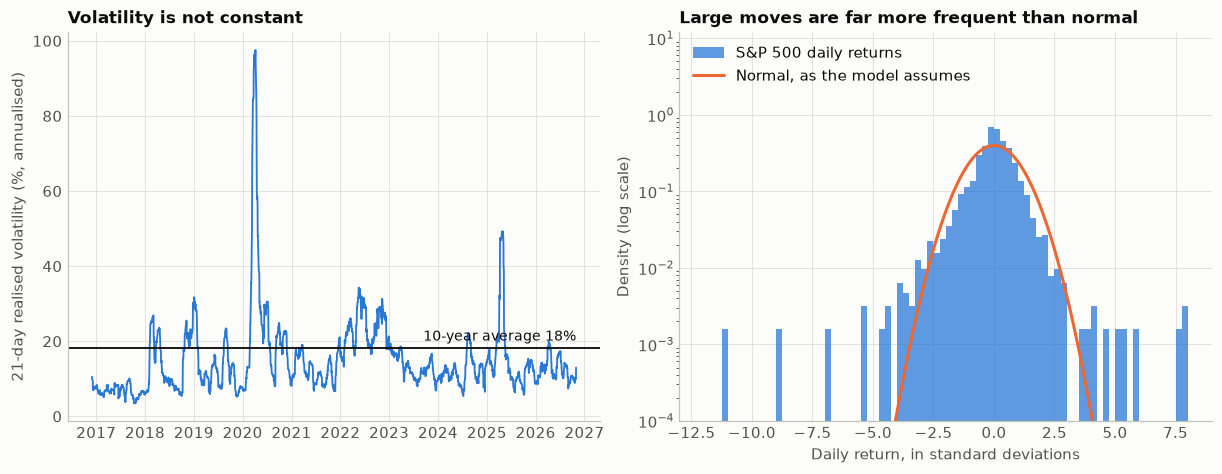

annual_vol                 0.1814
excess_kurtosis            16.6941
worst_day                  -0.1277
worst_day_in_sd            -11.1700
days_beyond_4sd            17
expected_days_beyond_4sd   0.1592
rolling_vol_min            0.0347
rolling_vol_median         0.1246
rolling_vol_max            0.9756
n_days                     2,513
one-year ATM implied vol   0.1749
ATM 1Y minus realised 21d  0.0450 (latest 21d realised 0.1300)


In [13]:
if snapshot is not None:
    stats = return_statistics(close)
    returns = np.log(close).diff().dropna()
    rolling = returns.rolling(21).std().dropna() * np.sqrt(252)
    one_year_atm = summary["atm_vol"].iloc[-1]

    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
    left.plot(rolling.index, rolling * 100, color=BLUE, linewidth=1.2)
    left.axhline(stats["annual_vol"] * 100, color=INK, linewidth=1.2)
    left.annotate(f"10-year average {stats['annual_vol']:.0%}", (rolling.index[-1], stats["annual_vol"] * 100), xytext=(0, 5), textcoords="offset points", ha="right", color=INK, fontsize=9)
    left.set_title("Volatility is not constant")
    left.set_ylabel("21-day realised volatility (%, annualised)")

    z = (returns - returns.mean()) / returns.std()
    bins = np.arange(-12, 8.25, 0.25)
    right.hist(z, bins=bins, density=True, color=BLUE, alpha=0.75, label="S&P 500 daily returns")
    grid = np.linspace(-6, 6, 400)
    right.plot(grid, np.exp(-0.5 * grid**2) / np.sqrt(2 * np.pi), color=ORANGE, label="Normal, as the model assumes")
    right.set_yscale("log")
    right.set_ylim(1e-4, 12)
    right.set_title("Large moves are far more frequent than normal")
    right.set_xlabel("Daily return, in standard deviations")
    right.set_ylabel("Density (log scale)")
    right.legend(loc="upper left")
    fig.savefig(market_figures / "return_evidence.png")
    plt.show()

    for name, value in stats.items():
        print(f"{name:26} {value:,.4f}" if isinstance(value, float) else f"{name:26} {value:,}")
    print(f"{'one-year ATM implied vol':26} {one_year_atm:.4f}")
    print(f"{'ATM 1Y minus realised 21d':26} {one_year_atm - rolling.iloc[-1]:.4f} (latest 21d realised {rolling.iloc[-1]:.4f})")

**Reading the results.** All figures below are for the reference snapshot of 2026-10-30.

- **Black-Scholes fails this test.** One volatility should fit every strike. Instead, 1-month implied vol runs from about 13% at the 108% strike to about 30% at the 90% strike. The skew is at least 3.7 vol points at every maturity, against a median bid-ask width of 0.11, so it is not noise.
- **The market prices crashes.** A 1-month put 10% out of the money costs about 12 times its price at the at-the-money vol. A 1-month call 8.5% out of the money trades at about one seventh of its flat-vol price.
- **The ratio overstates the vol gap.** Far from the money, prices are very convex in vol, so a gap of 12 vol points becomes a large multiple. Vol points are the fairer unit for comparing strikes.
- **Skew fades with maturity.** The gap between the 90% strike and the money falls from 11.9 vol points at 1 month to 3.7 at 1 year. Crash risk is a large part of a short option's value and a small part of a long one's.
- **History points the same way.** Daily returns show 17 moves beyond 4 standard deviations in 10 years, where a normal distribution predicts 0.16. Realised volatility ranged from 3% to 98%. Both facts contradict the model's assumptions, and both help explain why the market charges more for downside protection.

**Limits of this evidence.** It is a single snapshot, taken on a day the index fell 2.36%, so the skew may be steeper than usual. Yahoo quotes are delayed and the file gives no exact time for each quote. The parity check removes stale quotes it can detect, but it cannot show that the remaining quotes are simultaneous. The explanation of skew as crash risk is the standard reading, but this data does not separate it from demand for hedging.

## 6. Bonus: American options on a binomial tree

The analysis above uses S&P 500 options because they are European. Most options on single stocks and ETFs are American, and the closed form does not price those. A Cox-Ross-Rubinstein tree does, and it gives a measure of how much that matters.

In [14]:
from bs_lab.binomial import crr_price

exact_put = put_price(100.0, K, 1.0, R, SIGMA)
steps = [10, 50, 100, 500, 1000, 5000]
tree_rows = [{"steps": n, "european_tree": crr_price(100.0, K, 1.0, R, SIGMA, n, "put", american=False),
              "american_tree": crr_price(100.0, K, 1.0, R, SIGMA, n, "put", american=True)} for n in steps]
tree_table = pd.DataFrame(tree_rows).assign(error_vs_closed_form=lambda t: t["european_tree"] - exact_put)
print(f"Closed-form European put: {exact_put:.4f}")
print(tree_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\nEarly-exercise premium of a 1-year put (American minus European, as % of the European price):")
for rate in (0.0, 0.02, 0.05):
    row = []
    for strike in (90.0, 100.0, 110.0):
        american = crr_price(100.0, strike, 1.0, rate, SIGMA, 1000, "put", american=True)
        european = crr_price(100.0, strike, 1.0, rate, SIGMA, 1000, "put", american=False)
        row.append(f"K={strike:.0f}: {american / european - 1:6.2%}")
    print(f"  r = {rate:.0%}  " + "  ".join(row))

Closed-form European put: 6.4580
 steps  european_tree  american_tree  error_vs_closed_form
    10         6.2624         6.6425               -0.1956
    50         6.4184         6.7233               -0.0396
   100         6.4381         6.7332               -0.0198
   500         6.4540         6.7411               -0.0040
  1000         6.4560         6.7420               -0.0020
  5000         6.4576         6.7428               -0.0004

Early-exercise premium of a 1-year put (American minus European, as % of the European price):
  r = 0%  K=90:  0.00%  K=100:  0.00%  K=110:  0.00%
  r = 2%  K=90:  1.96%  K=100:  2.53%  K=110:  3.21%


  r = 5%  K=90:  7.01%  K=100:  9.30%  K=110: 12.15%


**Reading the table.** The tree converges to the closed form for a European put, which validates it. The early-exercise premium grows with the rate and with moneyness, and it vanishes when the rate is zero, because exercising a put early only pays by earning interest on the strike sooner. It is one reason to use a European underlying for a test of the model: applying the closed form to American quotes would mix this premium into the implied vol.